In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp


import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots
import tqdm

plt.style.use("ICIWstyle")
plt.rcParams.update(
    {
        "figure.dpi": 600,
        "font.size": 7,
        # "axes.linewidth": 0.8,
        # "axes.spines.top": False,
        # "axes.spines.right": False,
        # "axes.grid": False,
        # "legend.frameon": False,
    }
)
%config InlineBackend.print_figure_kwargs = {'bbox_inches':None}


In [2]:
# from HSA_B_039 import kl_divergence_between_models
from HSA_Mo_B_011 import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior,
    TRUE_PARAMS,
)

In [3]:
ov = [
    {
        "ID": "H_001",
        "run_name": "verdant-stack",
        "dir": Path("data/verdant-stack"),
        "DOE": "Koschany DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "total_IGs": {},
    },
    {
        "ID": "K_001",
        "run_name": "selective-knight",
        "dir": Path("data/selective-knight"),
        "DOE": "paramEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "total_IGs": {},
    },
    {
        "ID": "K_002",
        "run_name": "square-guffaw",
        "dir": Path("data/square-guffaw"),
        "DOE": "predEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "total_IGs": {},
    },
    {
        "ID": "H_007",
        "run_name": "isolated-question",
        "dir": Path("data/isolated-question"),
        "DOE": "LHS32 DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "total_IGs": {},
    },
    {
        "ID": "H_008",
        "run_name": "strong-cartwheel",
        "dir": Path("data/strong-cartwheel"),
        "DOE": "LHS64 DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "total_IGs": {},
    },
]

In [4]:
from scipy.special import logsumexp

PARAM_ORDER = (
    "k0",
    "Ea_k",
    "A_oh",
    "dH_oh",
    "A_h2",
    "dH_h2",
    "A_mix",
    "dH_mix",
    "sigma_r",
)
# Matches the likelihood in bayesian_model: sigma_obs = sigma_r * |r_pred| + 1e-10
SIGMA_FLOOR = 1e-10

# Draws used for the information-gain chain (32000 -> 8000 per trace).
IG_THIN = 4


def param_draws(idata, group="posterior", thin=1):
    """Stack chain/draw into an (M, 9) float64 array with columns in PARAM_ORDER."""
    stacked = az.extract(
        idata, group=group, var_names=list(PARAM_ORDER), num_samples=None
    )
    theta = np.stack(
        [np.asarray(stacked[v].values, dtype=np.float64).ravel() for v in PARAM_ORDER],
        axis=1,
    )
    return theta[::thin]


_PRIOR_DRAWS = None


def prior_draws(num_samples=32768):
    """Prior parameter draws, cached -- sample_prior is deterministic (PRNGKey(0))."""
    global _PRIOR_DRAWS
    if _PRIOR_DRAWS is None:
        _PRIOR_DRAWS = param_draws(sample_prior(num_samples=num_samples), group="prior")
    return _PRIOR_DRAWS


def obs_loglik(X, Y, theta):
    """(k, M) log-density of each observation under each parameter draw.

    Args:
        X: (k, 6) design rows [T, p, c2h, c2m, c2w, c2i]
        Y: (k,) observed rates
        theta: (M, 9) parameter draws ordered as PARAM_ORDER
    """
    cols = [jnp.asarray(X[:, j : j + 1]) for j in range(6)]
    p_i = calculate_partial_pressures(cols[1], cols[2], cols[3], cols[4], cols[5])
    r = np.asarray(
        kinetics_model(p_i, cols[0], *[jnp.asarray(theta[:, j]) for j in range(8)]),
        dtype=np.float64,
    )
    s = theta[:, 8][None, :] * np.abs(r) + SIGMA_FLOOR
    z = (Y[:, None] - r) / s
    return -0.5 * np.log(2.0 * np.pi * s**2) - 0.5 * z**2


def total_information_gain(X, Y, posterior_draws, prior_draws):
    """Total information gain KL( p(theta|D_i) || p(theta) ) for every iteration.

    Joint over the full 9-dimensional parameter vector, not a sum of marginals.
    The realised gain needs the evidence,

        KL( p(theta|D) || p(theta) ) = E_{p(theta|D)}[ log p(D|theta) ] - log p(D),

    which is tractable here because the datasets are NESTED, so the evidence ratio
    telescopes into one-step predictive densities,

        p(D_k) / p(D_{k-1}) = E_{p(theta|D_{k-1})}[ p(y_k | theta, x_k) ],

    each a single Monte Carlo average over a trace we already have. No density
    estimation and no Gaussian or copula assumption anywhere.

    Args:
        X: (n, 6) design matrix; row k is the condition of observation k
        Y: (n,) observations
        posterior_draws: list of length n, element k holding (M, 9) draws from
            p(theta | D_{k+1}). The k-th sorted trace is fit on the first k+1
            observations in both the trace_000.. and trace_001.. conventions.
        prior_draws: (M0, 9) draws from the prior, which plays the role of D_0

    Returns:
        dict of arrays indexed by iteration k = 0 .. n-1:
            ig            total gain vs the prior [nats]
            incremental   KL( p(theta|D_{k+1}) || p(theta|D_k) ) [nats]
            log_evidence  running log p(D_{k+1})
            log_pred      log predictive density of observation k+1 under the
                          previous posterior
            pred_ess      effective sample size behind log_pred; if this collapses
                          to a handful of draws that step's evidence is unreliable
    """
    n = len(posterior_draws)
    out = {k: [] for k in ("ig", "incremental", "log_evidence", "log_pred", "pred_ess")}

    log_evidence = 0.0  # log p(D_0) = 0, no data yet
    previous = prior_draws

    for k in range(n):
        # --- evidence increment: log E_{p(theta|D_k)}[ p(y_{k+1} | theta) ] ---
        ll_prev = obs_loglik(X[k : k + 1], Y[k : k + 1], previous)[0]
        log_pred = logsumexp(ll_prev) - np.log(len(ll_prev))
        log_evidence += log_pred

        # reliability of that average: ESS of the implied weights
        w = np.exp(ll_prev - ll_prev.max())
        pred_ess = w.sum() ** 2 / (w**2).sum()

        # --- E_{p(theta|D_{k+1})}[ log p(D_{k+1} | theta) ] ---
        theta = posterior_draws[k]
        mean_loglik = obs_loglik(X[: k + 1], Y[: k + 1], theta).sum(axis=0).mean()

        # step-wise gain KL( p(theta|D_{k+1}) || p(theta|D_k) ), computed directly
        incremental = obs_loglik(X[k : k + 1], Y[k : k + 1], theta)[0].mean() - log_pred

        out["ig"].append(mean_loglik - log_evidence)
        out["incremental"].append(incremental)
        out["log_evidence"].append(log_evidence)
        out["log_pred"].append(log_pred)
        out["pred_ess"].append(pred_ess)

        previous = theta

    return {key: np.asarray(val) for key, val in out.items()}

In [5]:
def get_seeds(ov_dict):
    master_file = ov_dict["dir"] / f"multi_seed_summary.json"
    with open(master_file, "r") as f:
        seed_summary = json.load(f)
    seeds = seed_summary["seeds_used"]
    ov_dict["seeds"] = seeds
    return seeds


def load_files(ov_dict, seed):
    """Load one seed of a campaign: traces, holdout validation and total IG."""
    seed_dir = ov_dict["dir"] / f"seed{seed:03d}"
    # glob rather than a fixed name: some runs carry the experiment id in the filename
    sum_file = list(seed_dir.glob("experiment_summary*.json"))[0]
    trace_files = sorted(seed_dir.glob("trace_*.nc"))
    test_data = xarray.open_dataset(ov_dict["holdout_data"])

    with open(sum_file, "r") as f:
        exp_summary = json.load(f)
    proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
    r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

    idatas = []
    valdatas = []
    posterior_draws = []
    for trace_file in tqdm.tqdm(
        trace_files, desc=f"{ov_dict['ID']} seed{seed:03d}", leave=False
    ):
        idata = az.from_netcdf(trace_file)
        idatas.append(idata)
        valdatas.append(
            validate_against_holdout(
                idata,
                test_data,
                num_samples=5000,
            )
        )
        posterior_draws.append(param_draws(idata, thin=IG_THIN))

    ig_res = total_information_gain(
        proposals,
        np.asarray(r_obs).ravel(),
        posterior_draws,
        prior_draws(),
    )

    ov_dict["idatas"][seed] = idatas
    ov_dict["valdatas"][seed] = valdatas
    ov_dict["proposals"][seed] = proposals
    ov_dict["r_obs"][seed] = r_obs
    ov_dict["total_IGs"][seed] = ig_res["ig"]

    # The evidence chain is only as good as the predictive averages behind it.
    min_ess = ig_res["pred_ess"].min()
    if min_ess < 50:
        weak = np.flatnonzero(ig_res["pred_ess"] < 50).tolist()
        print(
            f"  WARNING {ov_dict['ID']} seed{seed:03d}: predictive ESS below 50 at "
            f"iterations {weak} -- those evidence terms are unreliable, lower IG_THIN."
        )

In [ ]:
for ov_dict in ov:
    seeds = get_seeds(ov_dict)
    print(f"{ov_dict['ID']} ({ov_dict['run_name']}): seeds {seeds}")
    for seed in seeds:
        load_files(ov_dict, seed)

H_001 (verdant-stack): seeds [42, 43, 44, 45, 46]


K_001 (selective-knight): seeds [42, 43, 44, 45, 46]


K_002 (square-guffaw): seeds [42, 43, 44, 45, 46]


H_007 (isolated-question): seeds [42, 43, 44, 45, 46]


H_008 (strong-cartwheel): seeds [42, 43, 44, 45, 46]


H_008 seed044:  31%|███▏      | 20/64 [00:02<00:06,  7.25it/s]

In [ ]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    return rmse_vals


def calculate_RMSEs(ov_dict, seed):
    ov_dict["RMSEs"][seed] = np.array(
        [bRMSE(valdata, "r_pred") for valdata in ov_dict["valdatas"][seed]]
    )


for ov_dict in ov:
    for seed in ov_dict["seeds"]:
        calculate_RMSEs(ov_dict, seed)

for ov_dict in ov:
    seed = ov_dict["seeds"][0]
    print(
        f"{ov_dict['ID']:>6}  RMSEs{ov_dict['RMSEs'][seed].shape}  "
        f"total_IGs{ov_dict['total_IGs'][seed].shape}  "
        f"final IG {ov_dict['total_IGs'][seed][-1]:.2f} nats"
    )

 H_001  RMSEs(64, 5000)  total_IGs(64,)  final IG 17.33 nats
 K_001  RMSEs(32, 5000)  total_IGs(32,)  final IG 21.34 nats
 K_002  RMSEs(32, 5000)  total_IGs(32,)  final IG 18.25 nats
 H_007  RMSEs(32, 5000)  total_IGs(32,)  final IG 15.66 nats
 H_008  RMSEs(64, 5000)  total_IGs(64,)  final IG 18.97 nats


# RMSE Overview

Koschany DOE
(64, 2)
LHS32 DOE
(32, 2)
LHS64 DOE
(64, 2)


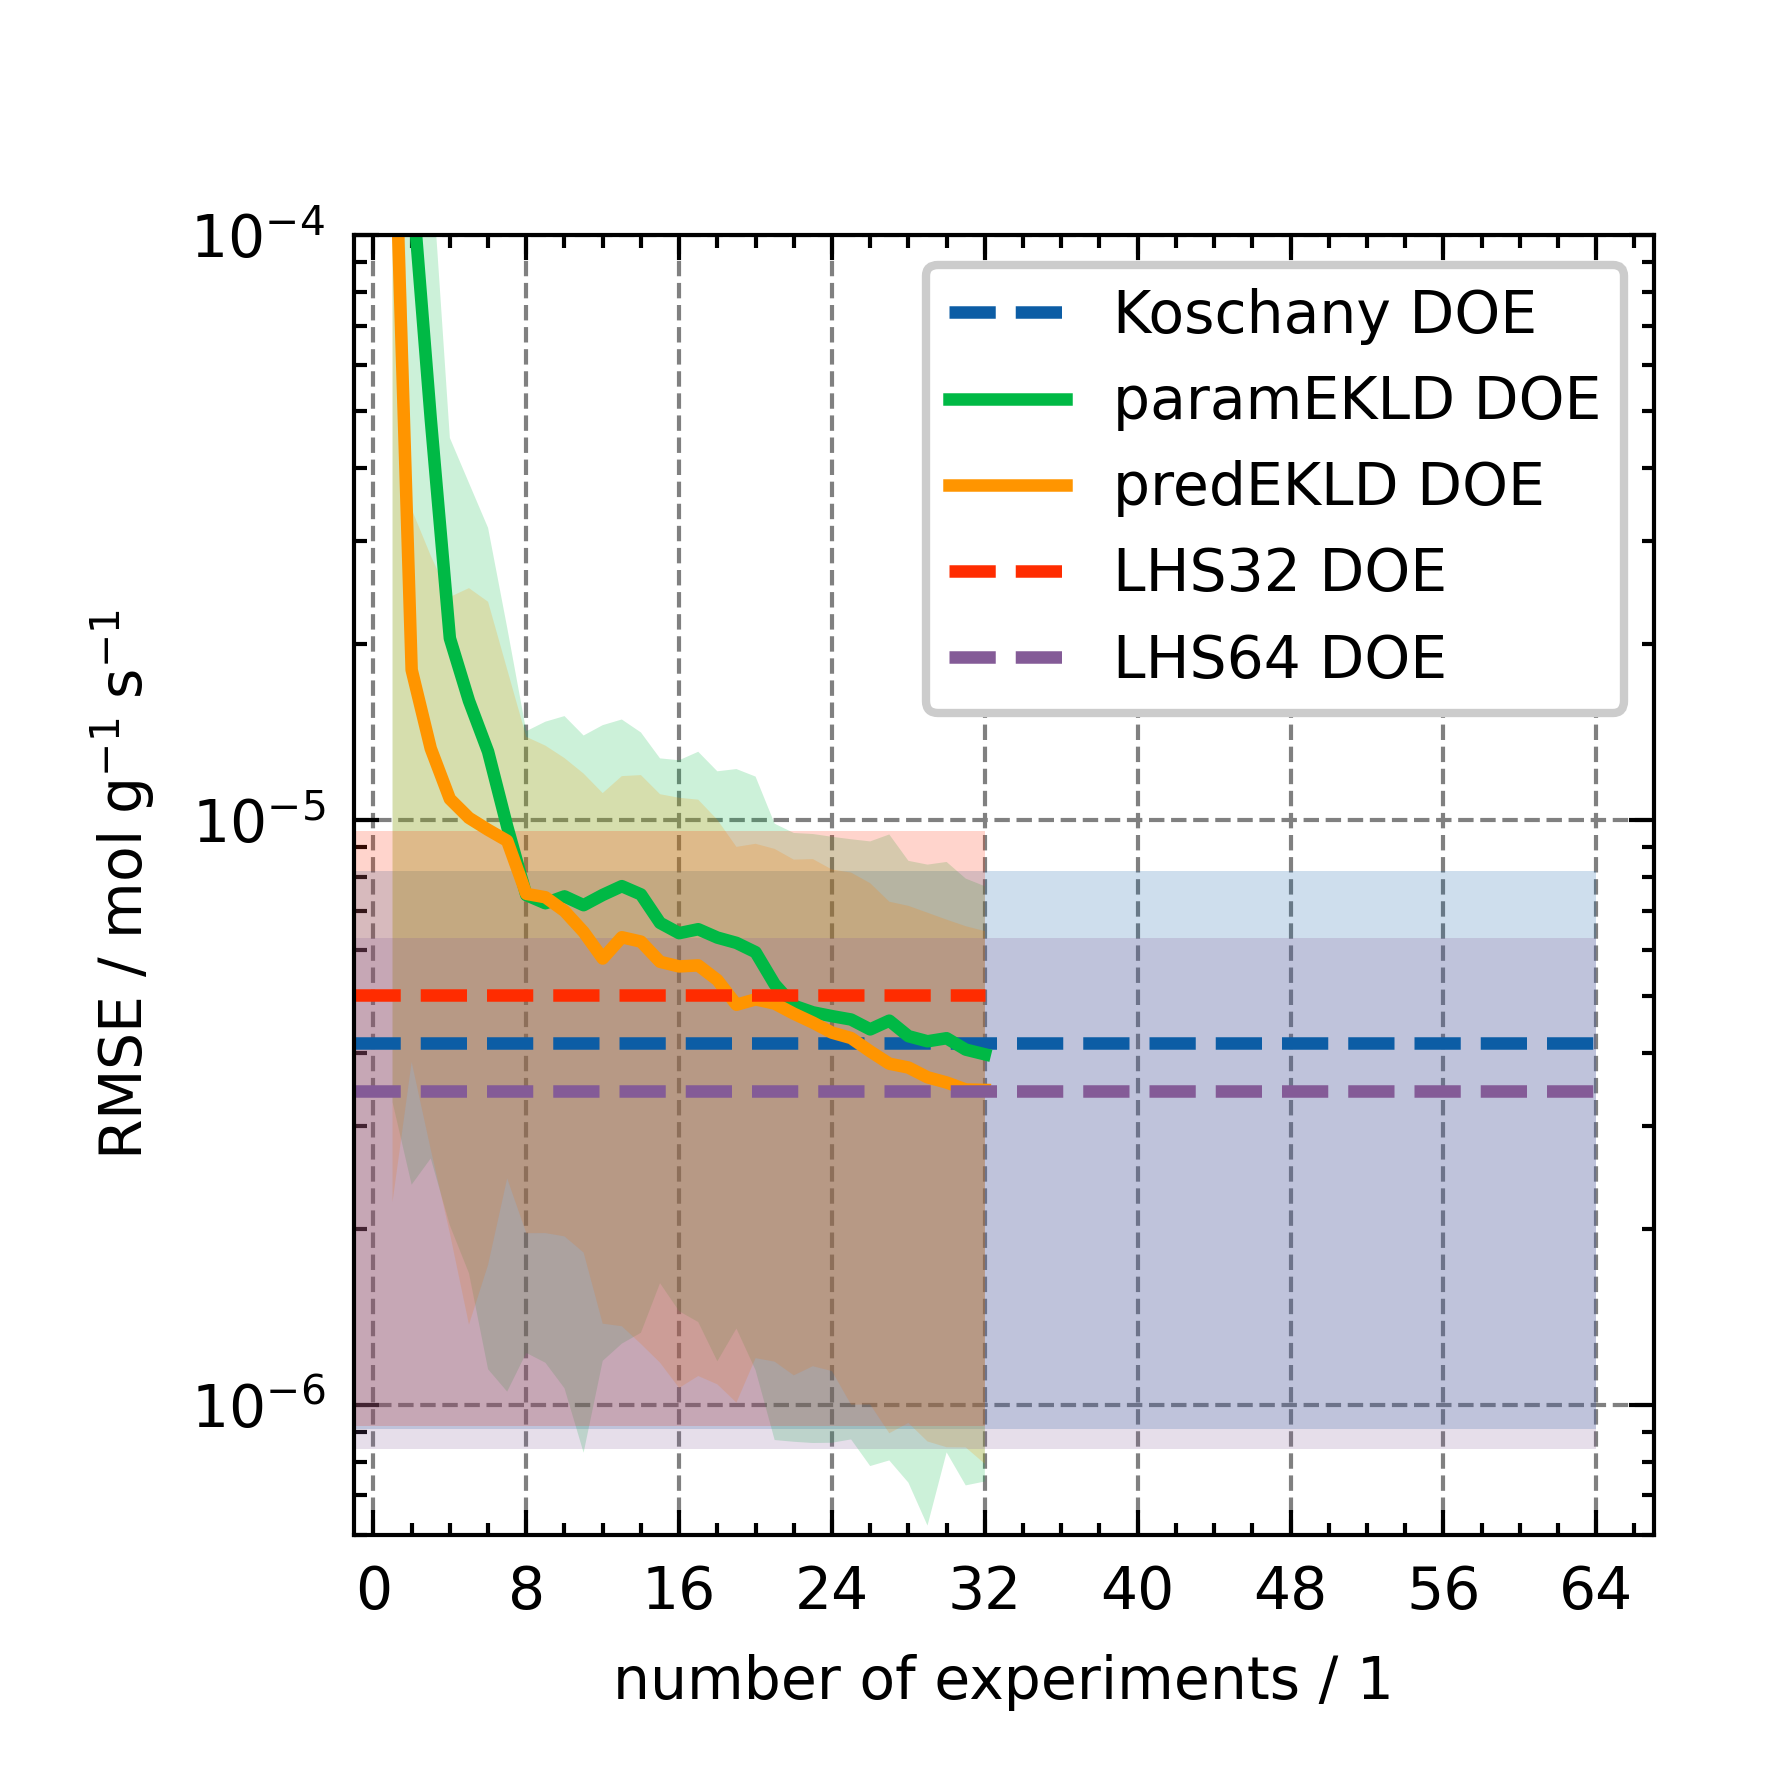

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    RMSEs = np.concatenate(
        [ov_dict["RMSEs"][seed] for seed in ov_dict["seeds"]], axis=-1
    )
    if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
        print(ov_dict["DOE"])
        xmax = len(ov_dict["RMSEs"][seed])
        ax.hlines(
            np.mean(RMSEs, axis=1)[-1],
            xmin=-1,
            xmax=xmax,
            label=ov_dict["DOE"],
            ls="--",
            color=colors[i],
        )
        HDI = az.hdi(
            RMSEs,
            prob=0.95,
            dim=0,
        )
        print(HDI.shape)
        ax.fill_between(
            np.arange(-1, RMSEs.shape[0] + 1),
            HDI[-1, 0],
            HDI[-1, 1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
        continue
    ax.plot(
        np.arange(1, RMSEs.shape[0] + 1),
        np.mean(RMSEs, axis=1),
        # "o--",
        # ms=4,
        # lw=1,
        label=ov_dict["DOE"],
        color=colors[i],
    )
    HDI = az.hdi(RMSEs, prob=0.95)
    ax.fill_between(
        np.arange(1, RMSEs.shape[0] + 1),
        HDI[:, 0],
        HDI[:, 1],
        alpha=0.2,
        # ls="--",
        facecolor=colors[i],
        # edgecolor="gray",
    )
ax.legend(frameon=True)

plt.savefig("figures/K/KinFit_RMSE.png")
plt.savefig("figures/K/KinFit_RMSE.pdf")
plt.savefig("figures/K/KinFit_RMSE.svg")

(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)


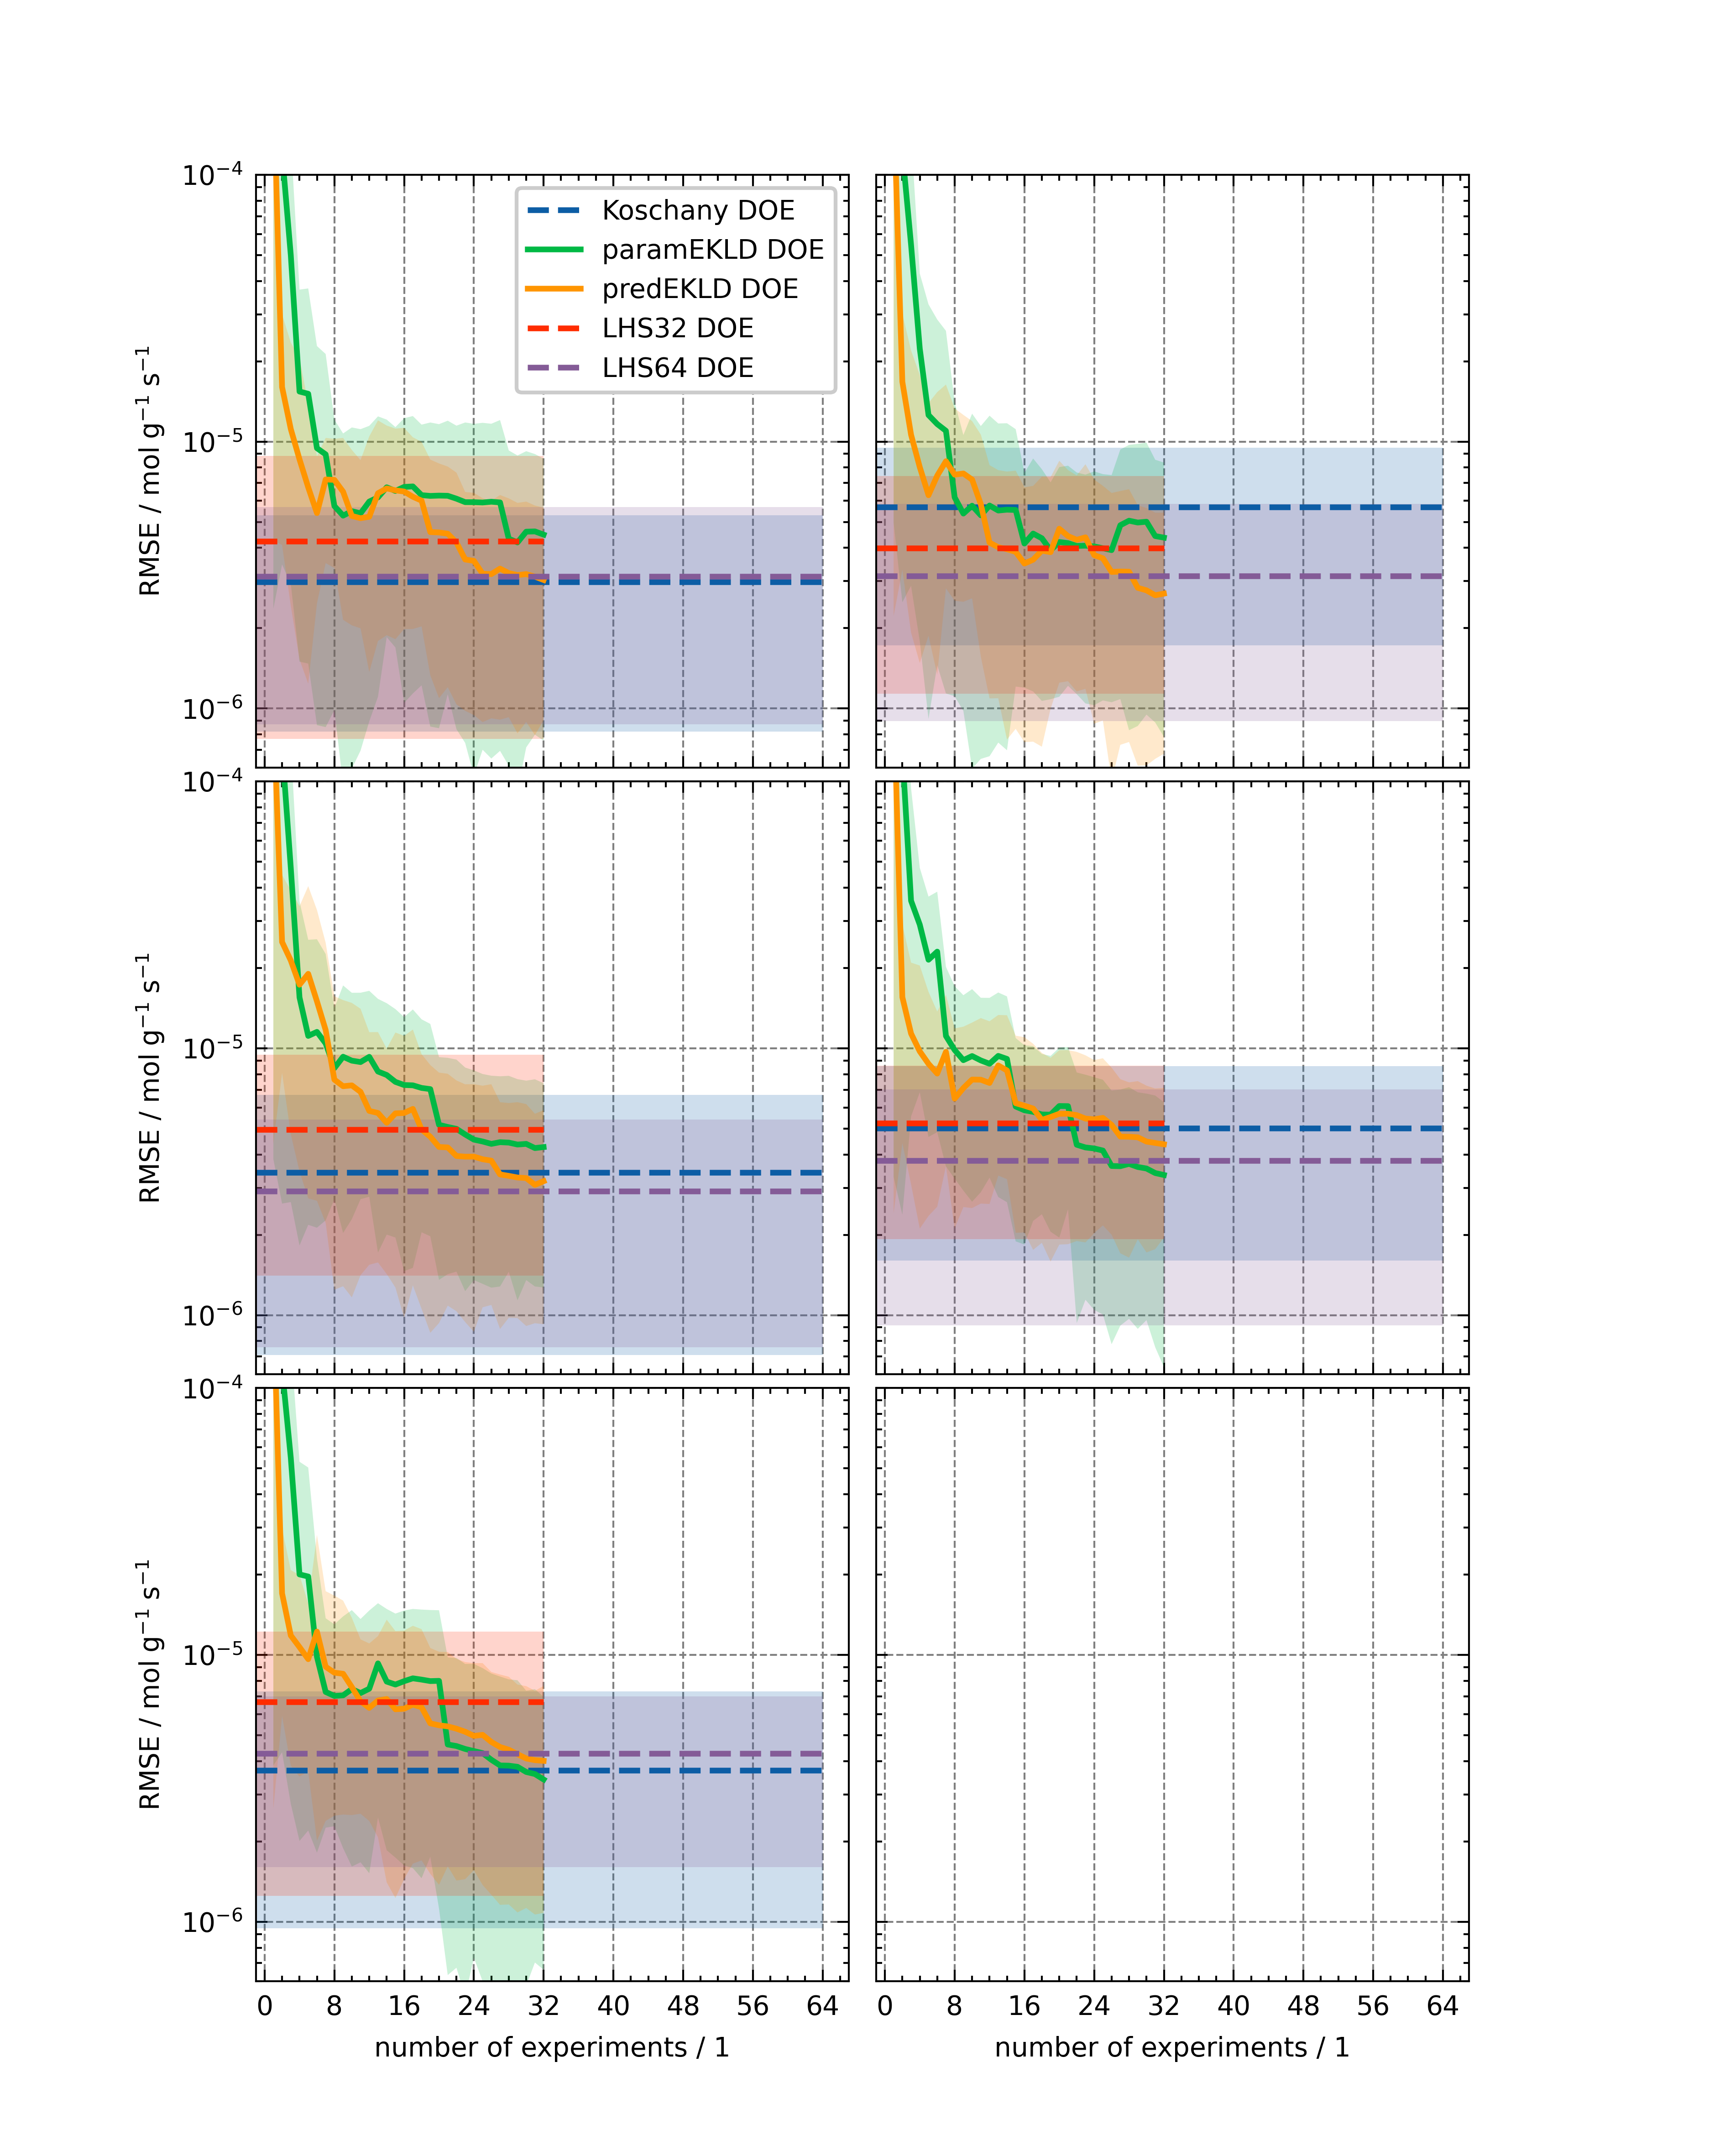

In [ ]:
fig = ICIW_Plots.figure(layout="double_column", height=20 * ICIW_Plots.cm2inch)
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(3, 2),
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    sharex=True,
    sharey=True,
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    # left_h=1.5 * ICIW_Plots.cm2inch,
    h_sep=0.1,
    sharelabel=True,
)
axs = axs.flatten()

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    for seed_idx, seed in enumerate(ov_dict["seeds"]):

        if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
            xmax = len(ov_dict["RMSEs"][seed])
            axs[seed_idx].hlines(
                np.mean(ov_dict["RMSEs"][seed], axis=1)[-1],
                xmin=-1,
                xmax=xmax,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            HDI = az.hdi(ov_dict["RMSEs"][seed][-1], prob=0.95)
            axs[seed_idx].fill_between(
                np.arange(-1, len(ov_dict["RMSEs"][seed]) + 1),
                HDI[0],
                HDI[1],
                alpha=0.2,
                # ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        axs[seed_idx].plot(
            np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
            np.mean(ov_dict["RMSEs"][seed], axis=1),
            # "o--",
            # ms=4,
            # lw=1,
            label=ov_dict["DOE"],
            color=colors[i],
        )
        HDI = az.hdi(ov_dict["RMSEs"][seed], prob=0.95)
        print(HDI.shape)
        axs[seed_idx].fill_between(
            np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
    axs[0].legend(frameon=True)

plt.savefig("figures/K/KinFit_RMSE_by_seed.png")
plt.savefig("figures/K/KinFit_RMSE_by_seed.pdf")
plt.savefig("figures/K/KinFit_RMSE_by_seed.svg")

# Information Gain

(64, 5)
(32, 5)
(32, 5)
(32, 5)
(64, 5)


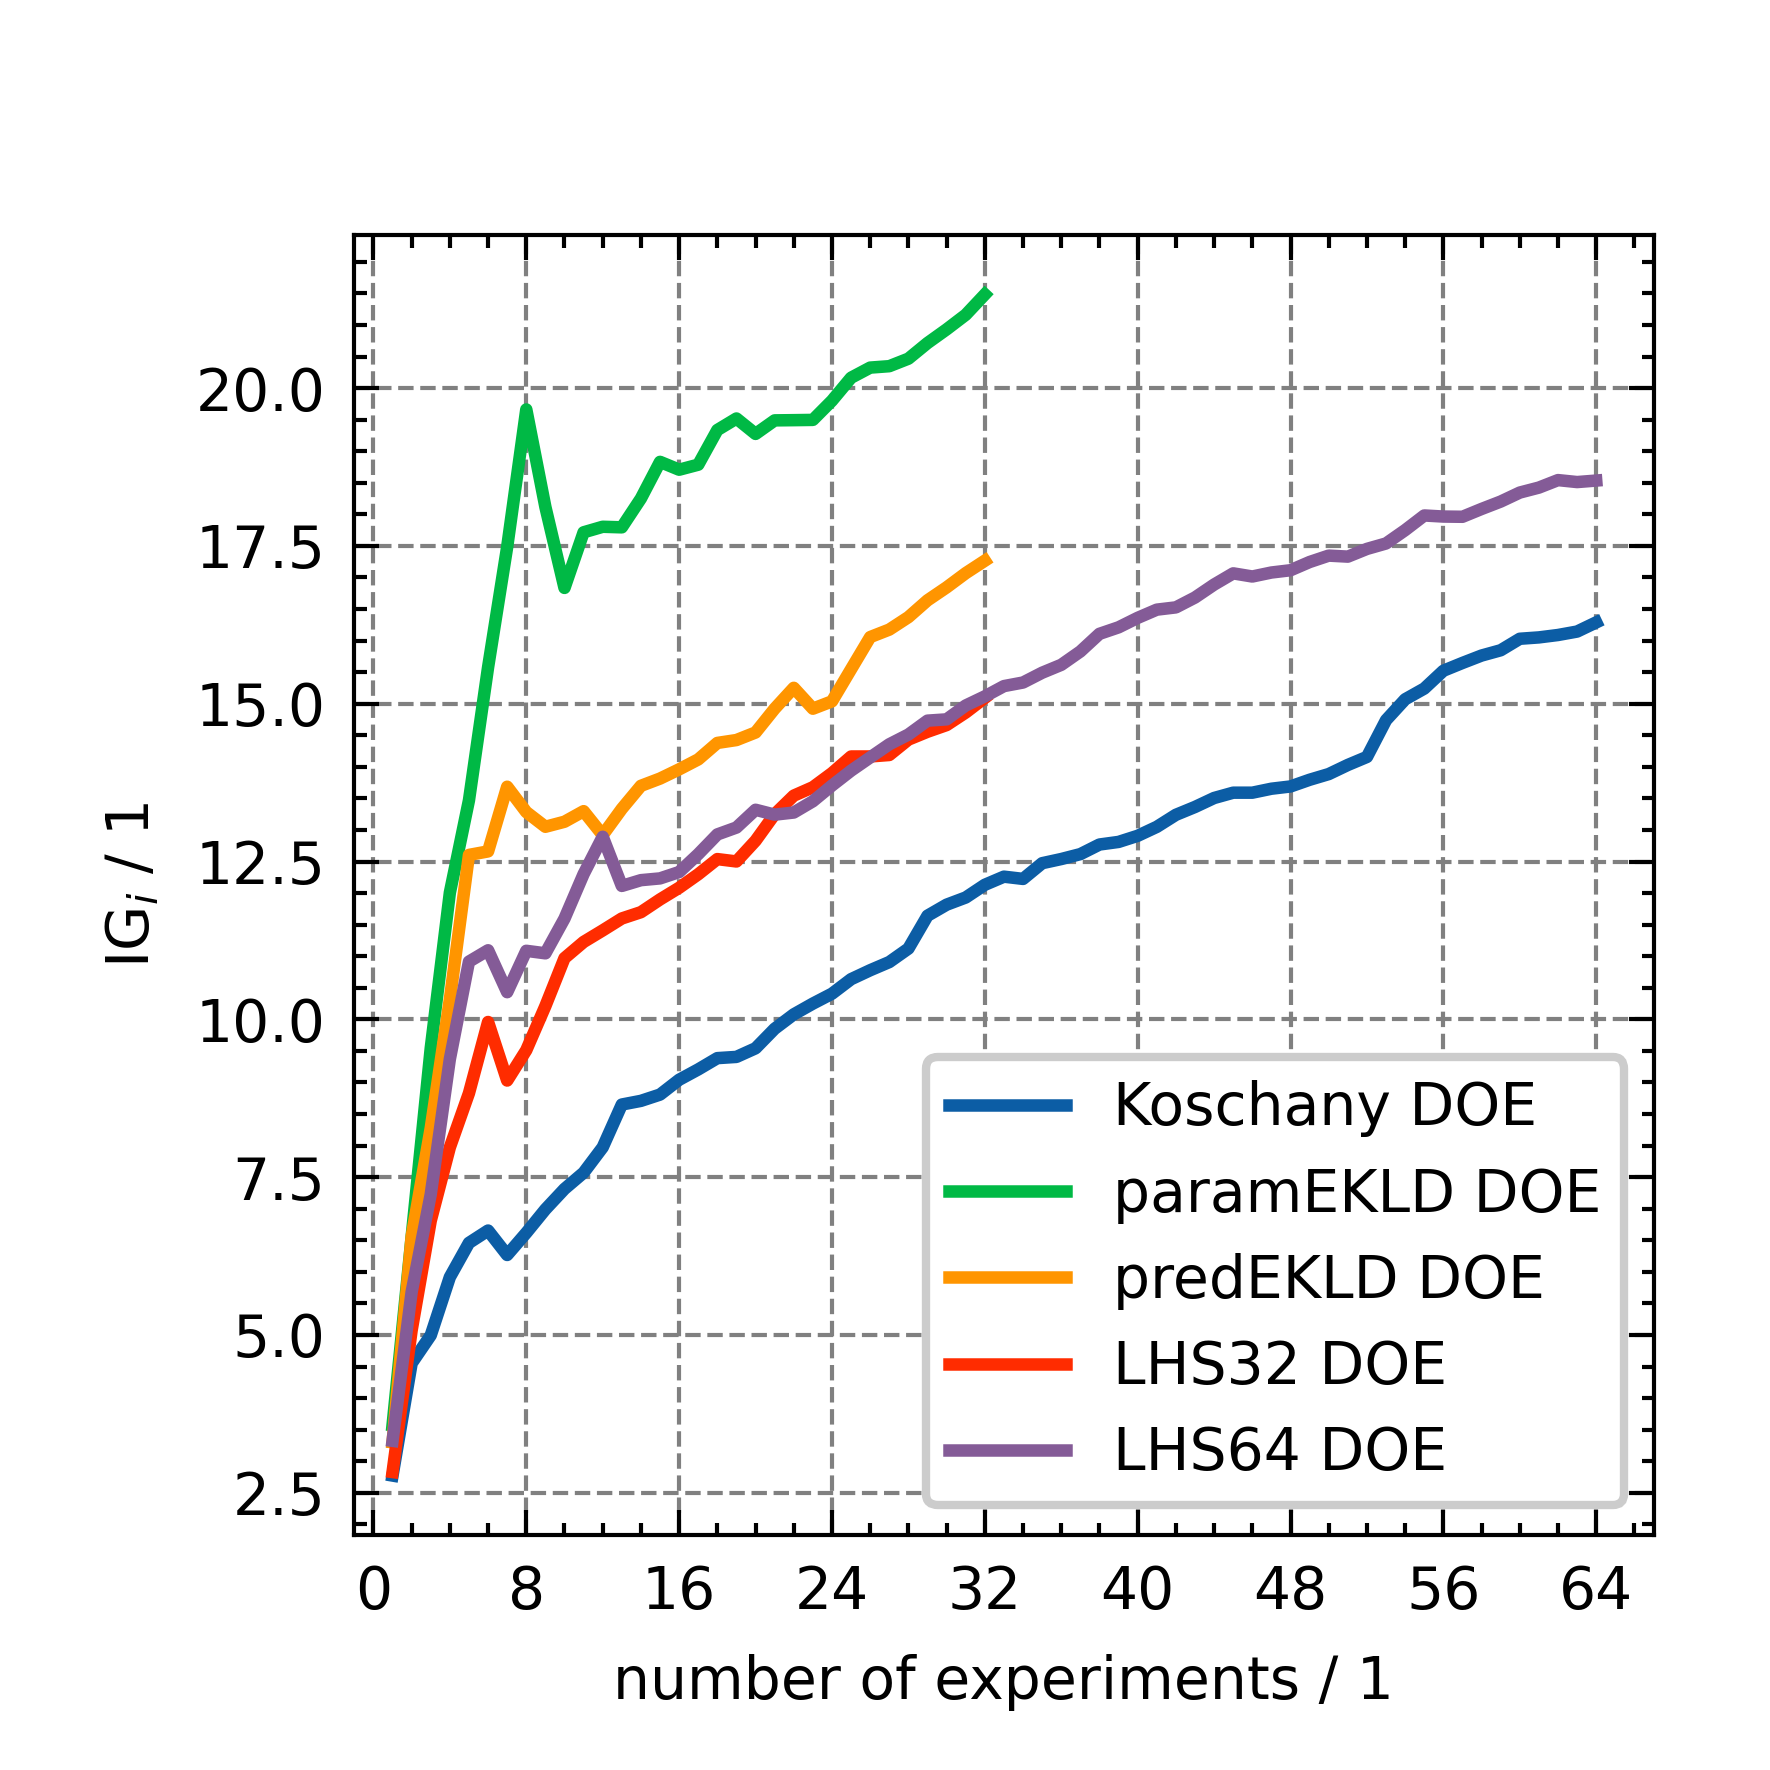

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
for i, ov_dict in enumerate(ov):
    IGs = np.stack([ov_dict["total_IGs"][seed] for seed in ov_dict["seeds"]], axis=-1)
    print(IGs.shape)
    ax.plot(
        np.arange(IGs.shape[0]) + 1,
        np.mean(IGs, axis=1),
        label=ov_dict["DOE"],
        color=colors[i],
    )
    ax.legend()

plt.savefig("figures/K/KinFit_IG.png")
plt.savefig("figures/K/KinFit_IG.pdf")
plt.savefig("figures/K/KinFit_IG.svg")

(64, 5)
(32, 5)
(32, 5)
(32, 5)
(64, 5)


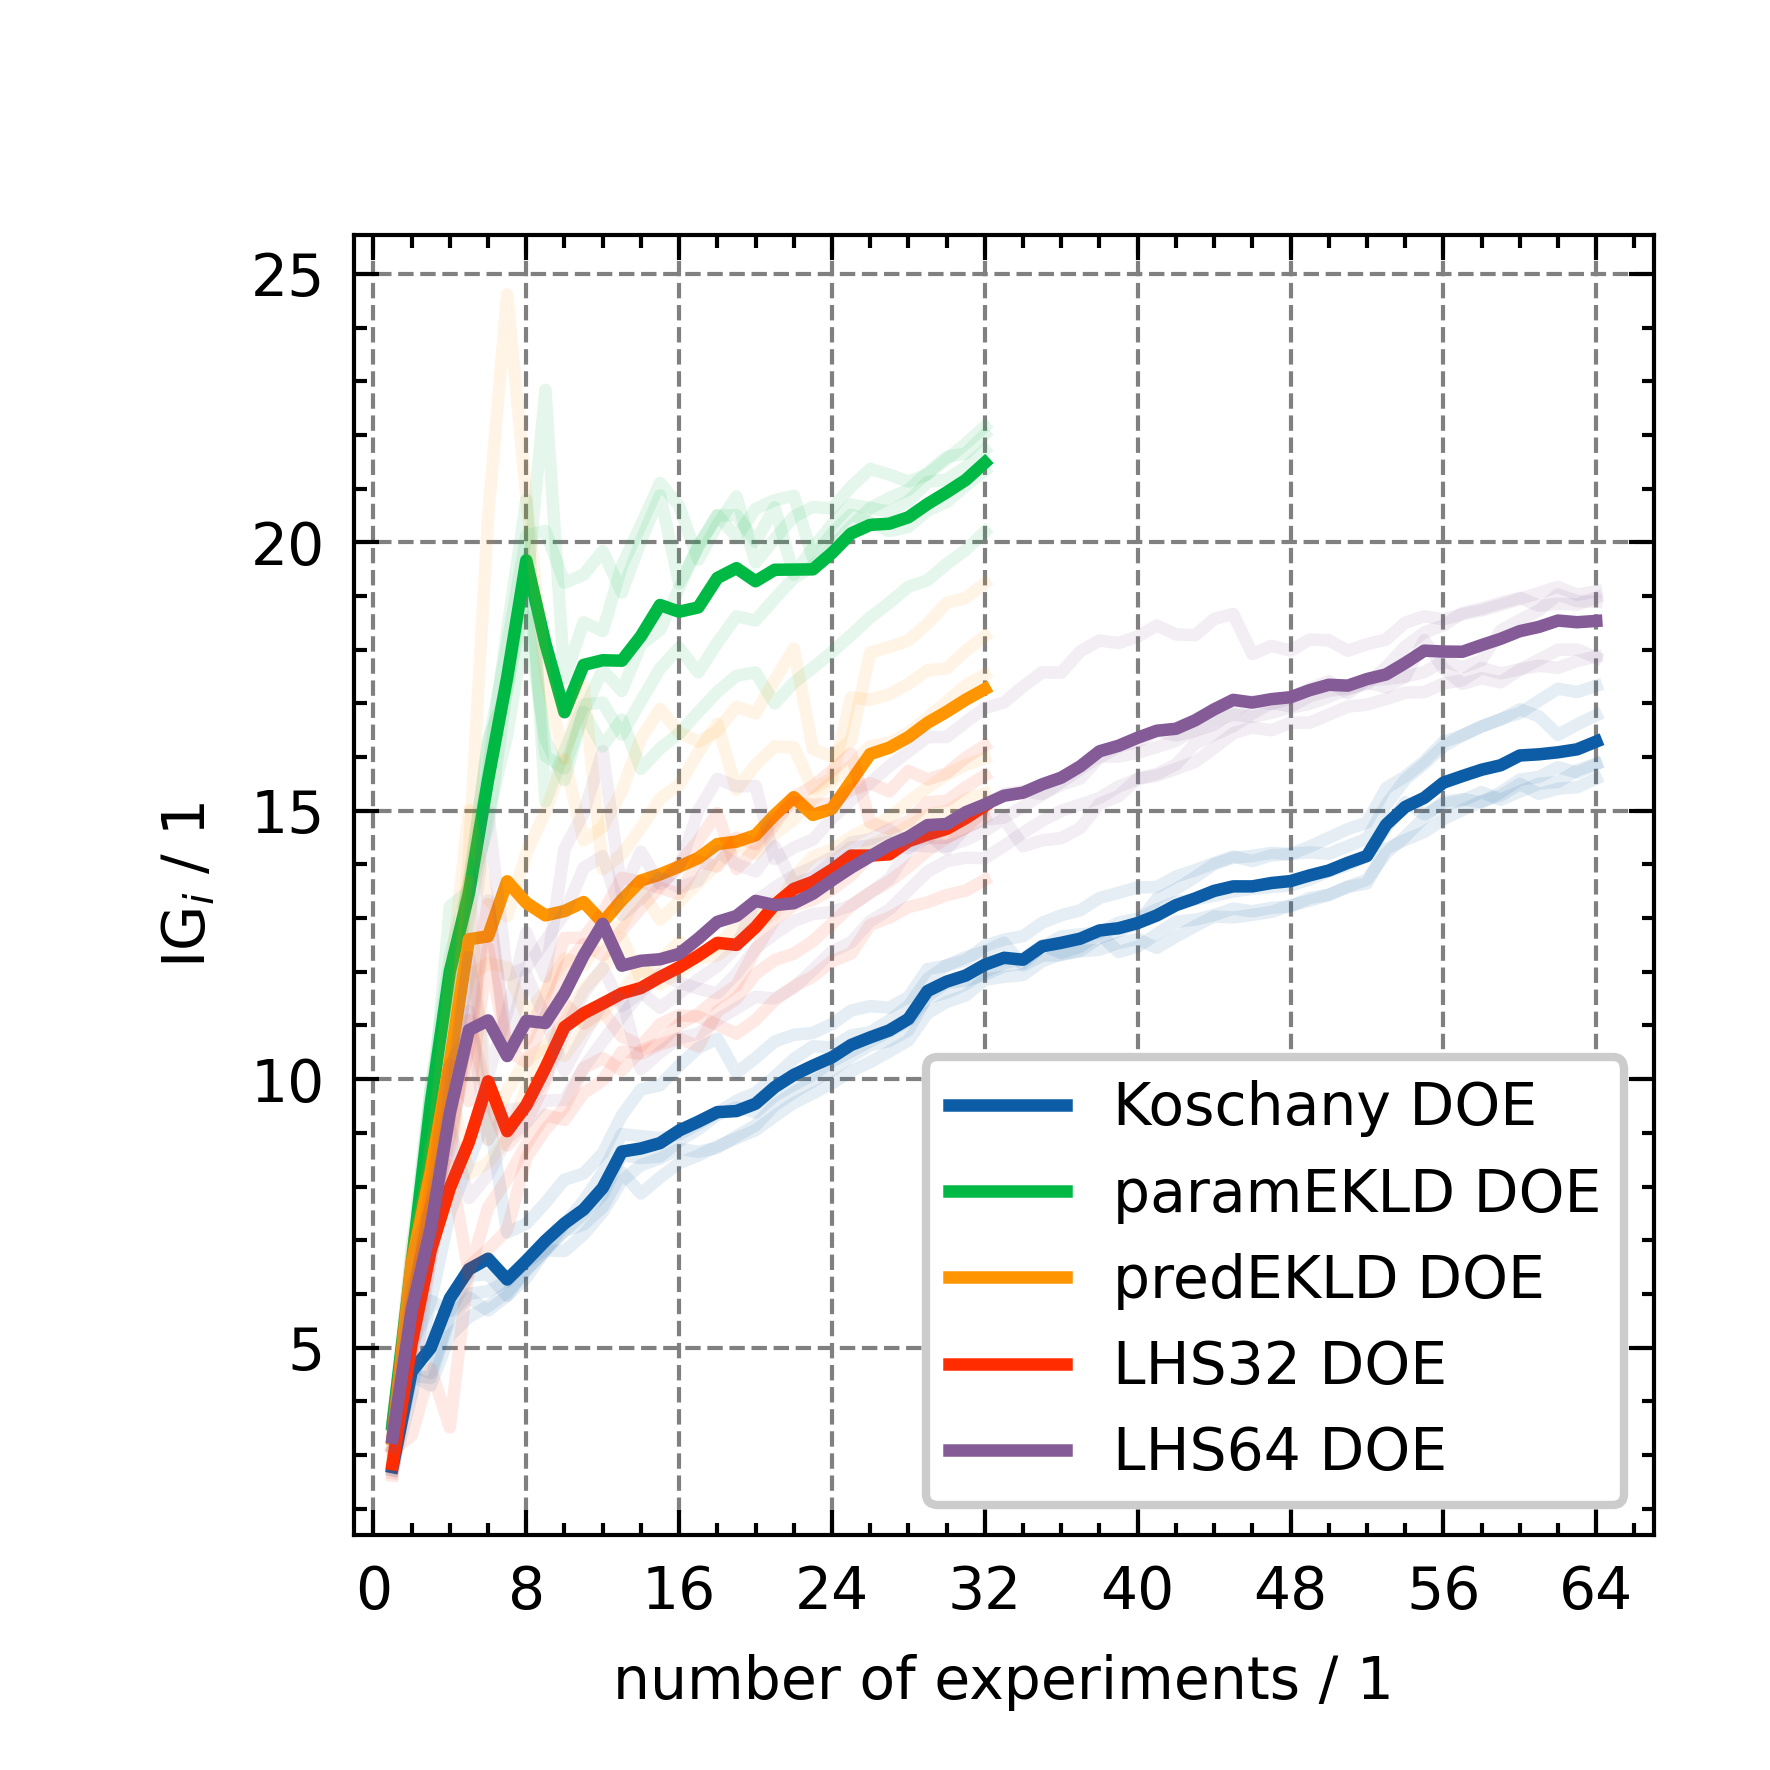

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
for i, ov_dict in enumerate(ov):
    IGs = np.stack([ov_dict["total_IGs"][seed] for seed in ov_dict["seeds"]], axis=-1)
    print(IGs.shape)
    ax.plot(
        np.arange(IGs.shape[0]) + 1,
        IGs,
        # label=ov_dict["DOE"],
        color=colors[i],
        alpha=0.1,
    )
    ax.plot(
        np.arange(IGs.shape[0]) + 1,
        np.mean(IGs, axis=1),
        label=ov_dict["DOE"],
        color=colors[i],
    )
    ax.legend()

# plt.savefig("figures/rev/KinFit_IG.png")
# plt.savefig("figures/rev/KinFit_IG.pdf")
# plt.savefig("figures/rev/KinFit_IG.svg")

# Parameter distributions

Final posterior for each kinetic parameter, one violin per DOE, against the ground truth.

In [ ]:
def collect_param_samples_by_seed_and_step(ov_dict, key, group="posterior"):
    """Return posterior samples with explicit seed and step dimensions."""
    per_seed = []
    for seed in ov_dict["seeds"]:
        per_step = []
        for step, idata in enumerate(ov_dict["idatas"][seed]):
            samples = idata[group][key].stack(sample=("chain", "draw")).values
            per_step.append(
                xarray.DataArray(
                    samples,
                    dims=("sample",),
                    coords={"sample": np.arange(samples.size)},
                ).expand_dims(step=[step])
            )
        per_seed.append(xarray.concat(per_step, dim="step").expand_dims(seed=[seed]))
    return xarray.concat(per_seed, dim="seed")


param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}
# These are stored in J/mol but read better in kJ/mol
KJ_PARAMS = ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")


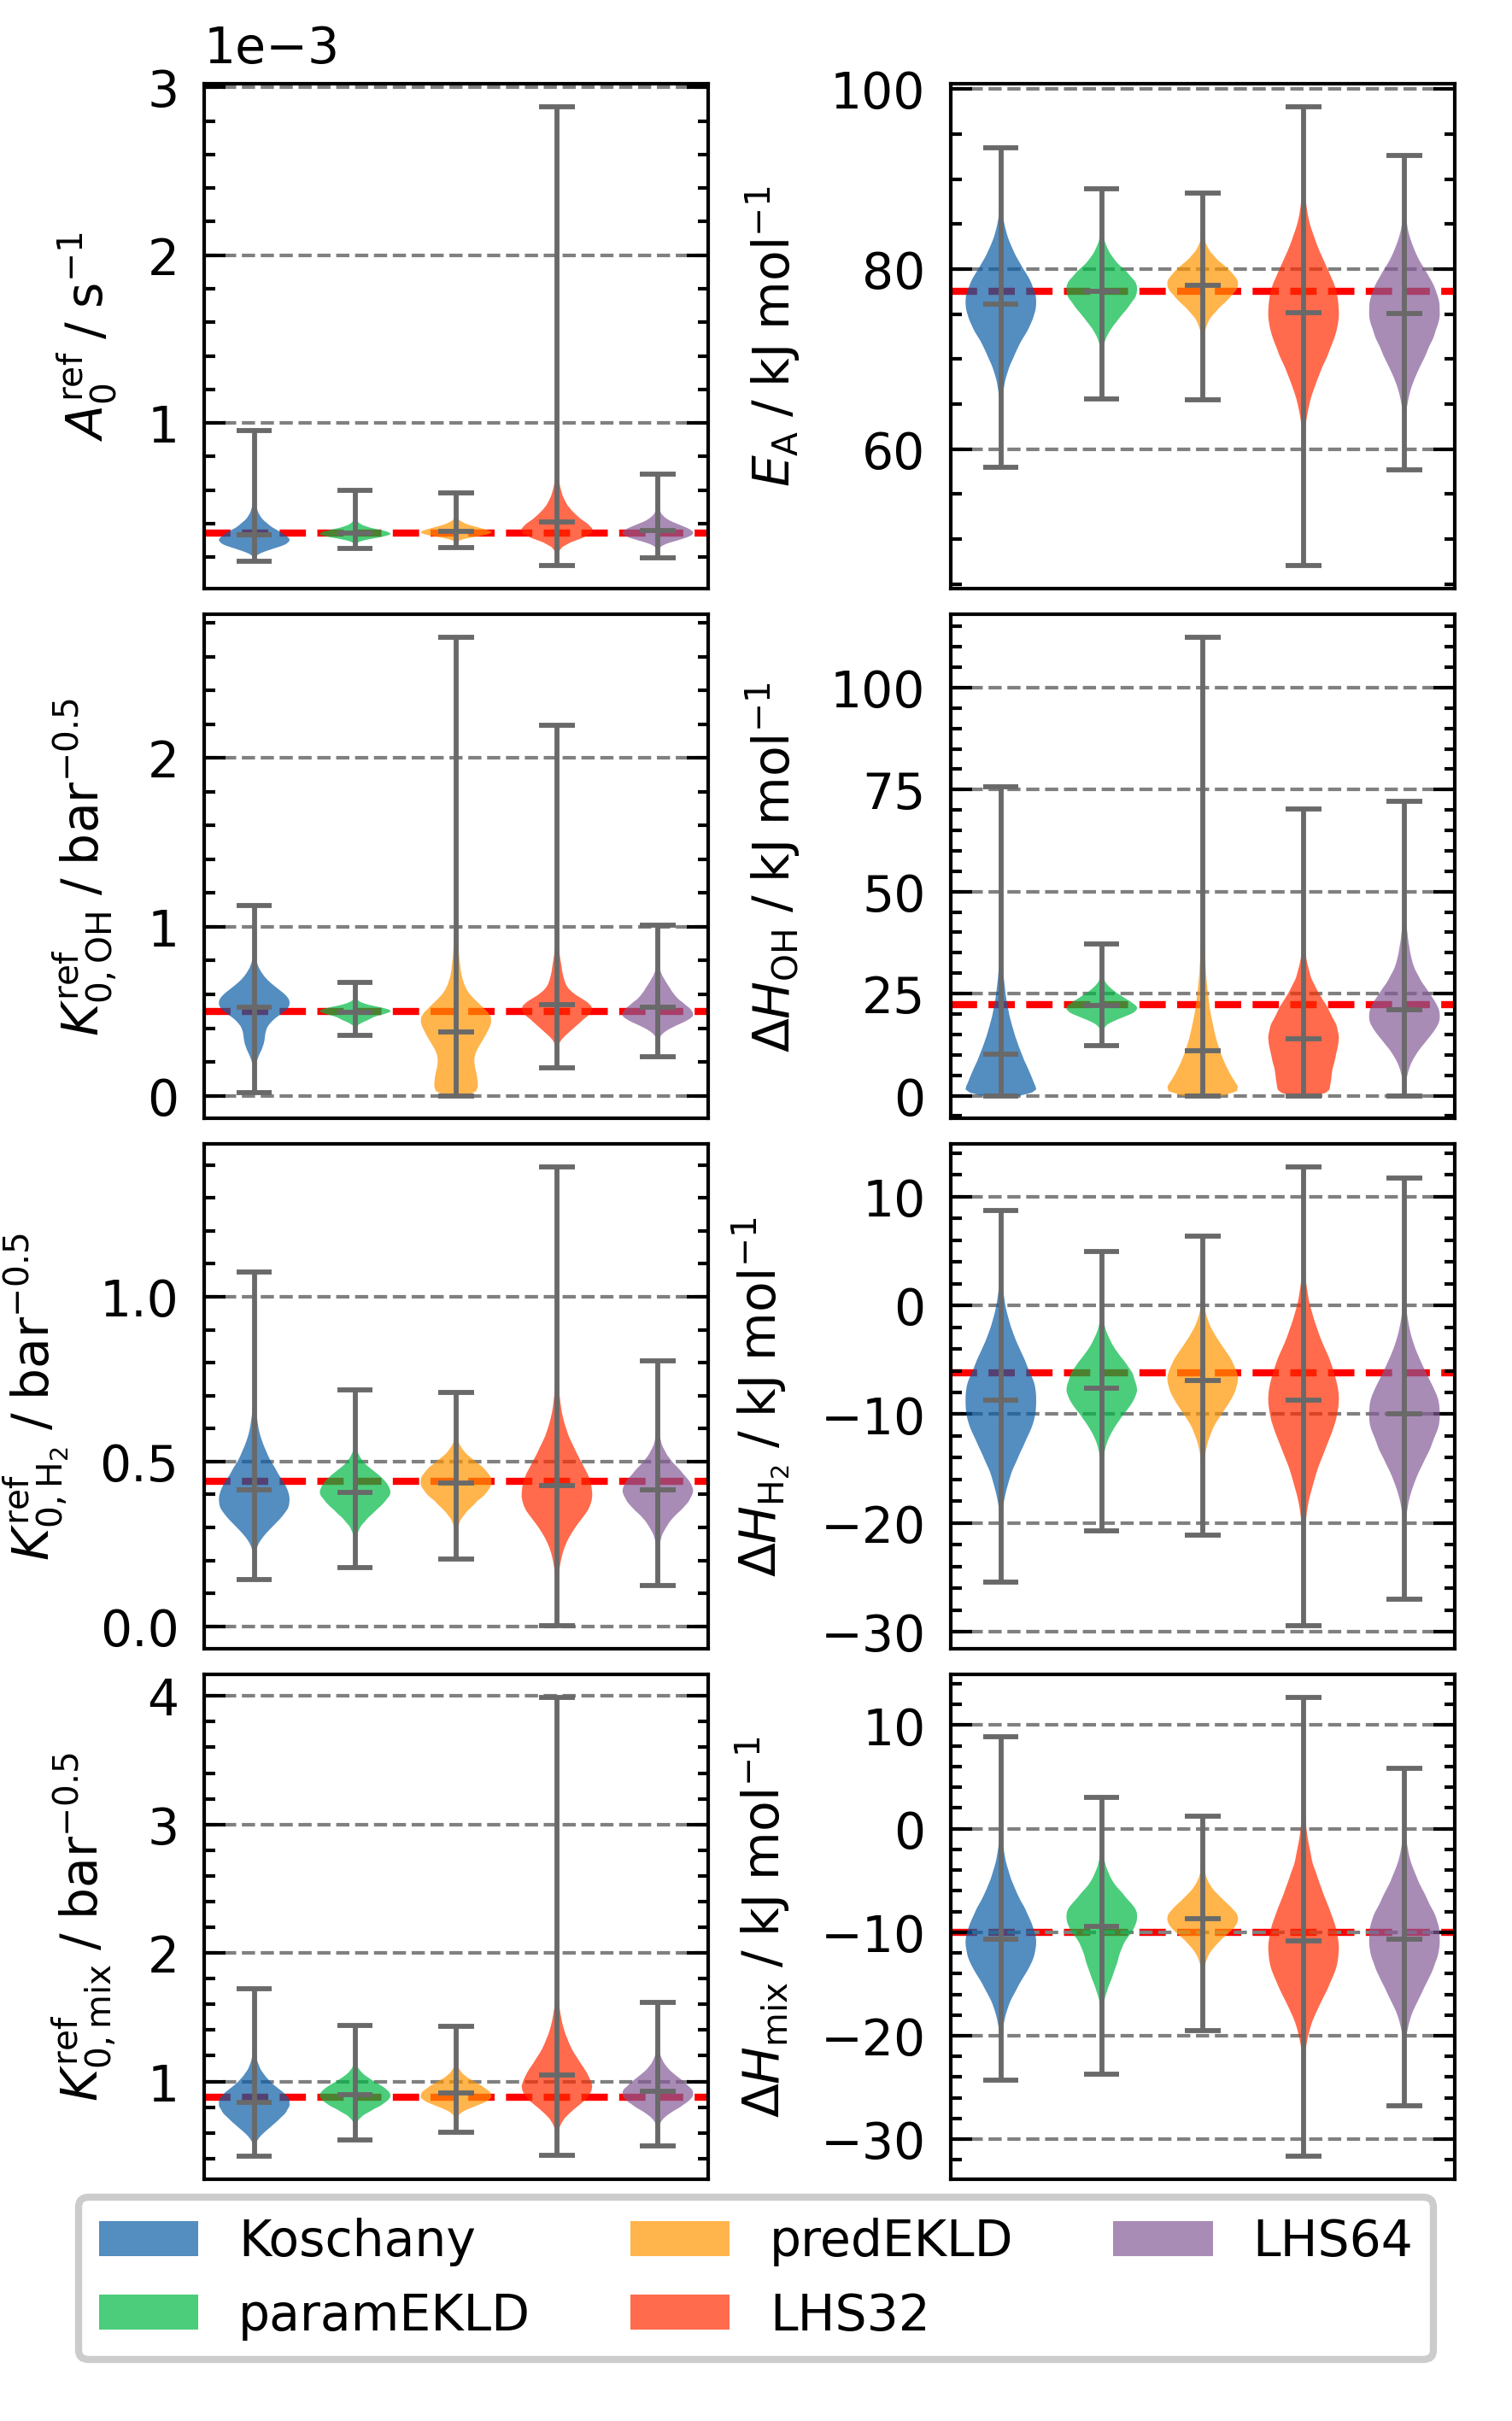

In [ ]:
from matplotlib.patches import Patch

fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.5 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.2 * ICIW_Plots.cm2inch,
    left_h=1.01 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # One violin per DOE, using the final posterior of each campaign
    violin_data = []
    for ov_dict in ov:
        samples = collect_param_samples_by_seed_and_step(ov_dict, param)
        samples = samples.isel(step=-1).stack(flat=("seed", "sample")).values
        if param in KJ_PARAMS:
            samples = samples * 1e-3
        violin_data.append(samples)

    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:
            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Colour the violins, one colour per DOE
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)

    # Ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in KJ_PARAMS:
        true_val = true_val * 1e-3
    ax.axhline(
        y=true_val,
        color="red",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")
    ax.set_xticks([])
    ax.set_xticklabels([])
    ax.grid(False, axis="x")
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# Legend built from ov, so it stays correct as campaigns are added or removed
legend_elements = [
    Patch(facecolor=colors[i], alpha=0.7, label=ov_dict["DOE"][:-4])
    for i, ov_dict in enumerate(ov)
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=min(len(ov), 3),
    frameon=True,
    bbox_to_anchor=(0.5, 0.015),
)

# Distinct filename: KinFit_parameter_comparison.* belongs to the H-series overview
plt.savefig("figures/K/KinFit_parameter_comparison.png")
plt.savefig("figures/K/KinFit_parameter_comparison.svg")
plt.savefig("figures/K/KinFit_parameter_comparison.pdf")
plt.show()

# Parameter courses

In [ ]:
from ipywidgets import interact, Dropdown

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}


@interact(
    key=Dropdown(
        options=keydict.keys(),
        value="k0",
        description="Parameter:",
    ),
)
def plot_parameter_evolution(key):
    fig = ICIW_Plots.figure()
    ax = ICIW_Plots.make_square_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        xlabel="number of experiments / 1",
        ylabel=f"{keydict[key]} / units",
        yscale="log",
        # ylim=(6e-7, 1e-4),
        # xlim=(-1, 67),
        xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
        left_h=1.5 * ICIW_Plots.cm2inch,
    )
    # ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    for i, ov_dict in enumerate(ov):
        param_samples = collect_param_samples_by_seed_and_step(ov_dict, key)
        ax.axhline(
            y=TRUE_PARAMS[keydict[key]],
            color="gray",
            linestyle="dashed",
            zorder=0,
        )
        if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
            xmax = param_samples.sizes["step"]
            ax.hlines(
                param_samples.mean(dim=("sample", "seed"))[-1],
                xmin=-1,
                xmax=xmax,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            HDI = az.hdi(param_samples, prob=0.95, dim=("sample", "seed")).isel(step=-1)
            ax.fill_between(
                np.arange(-1, param_samples.sizes["step"] + 1),
                HDI[0],
                HDI[1],
                alpha=0.2,
                # ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        ax.plot(
            np.arange(1, param_samples.sizes["step"] + 1),
            param_samples.mean(dim=("sample", "seed")),
            label=ov_dict["DOE"],
            color=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
        HDI = az.hdi(param_samples, prob=0.95, dim=("sample", "seed"))
        ax.fill_between(
            np.arange(1, param_samples.sizes["step"] + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            facecolor=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
    ax.legend(frameon=True)

interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

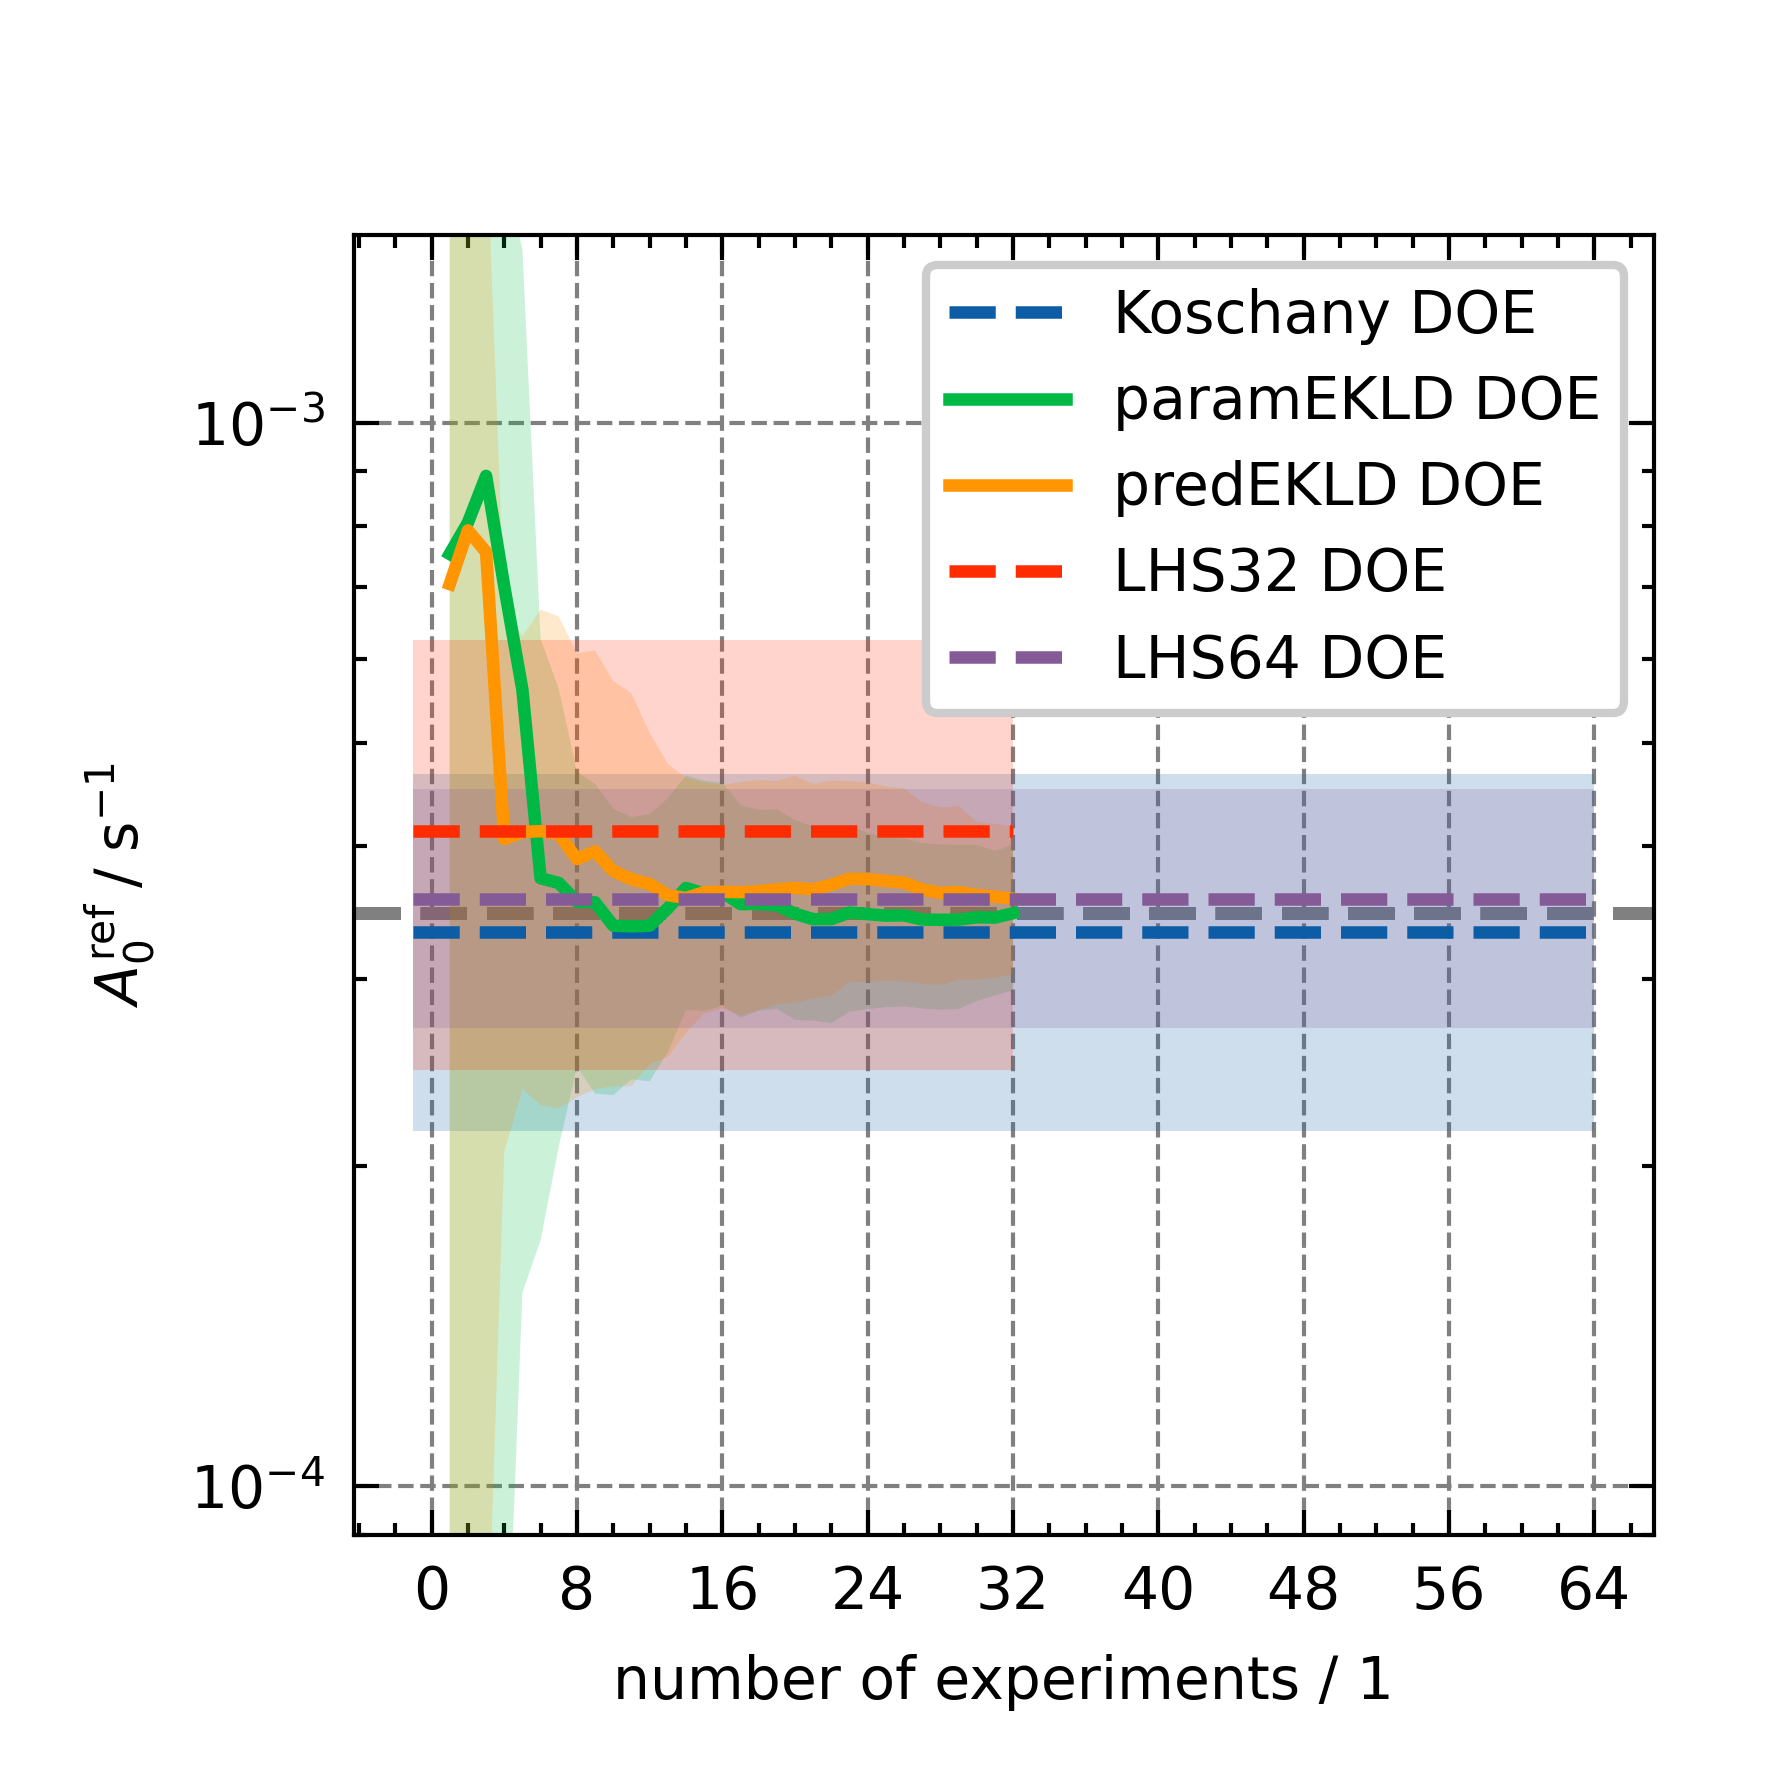

In [ ]:
plot_parameter_evolution("k0")
ax = plt.gca()
ax.set_ylabel(r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$")
ax.set_ylim(9e-5, 1.5e-3)
plt.savefig("figures/K/KinFit_k0_evolution.png")
plt.savefig("figures/K/KinFit_k0_evolution.pdf")
plt.savefig("figures/K/KinFit_k0_evolution.svg")

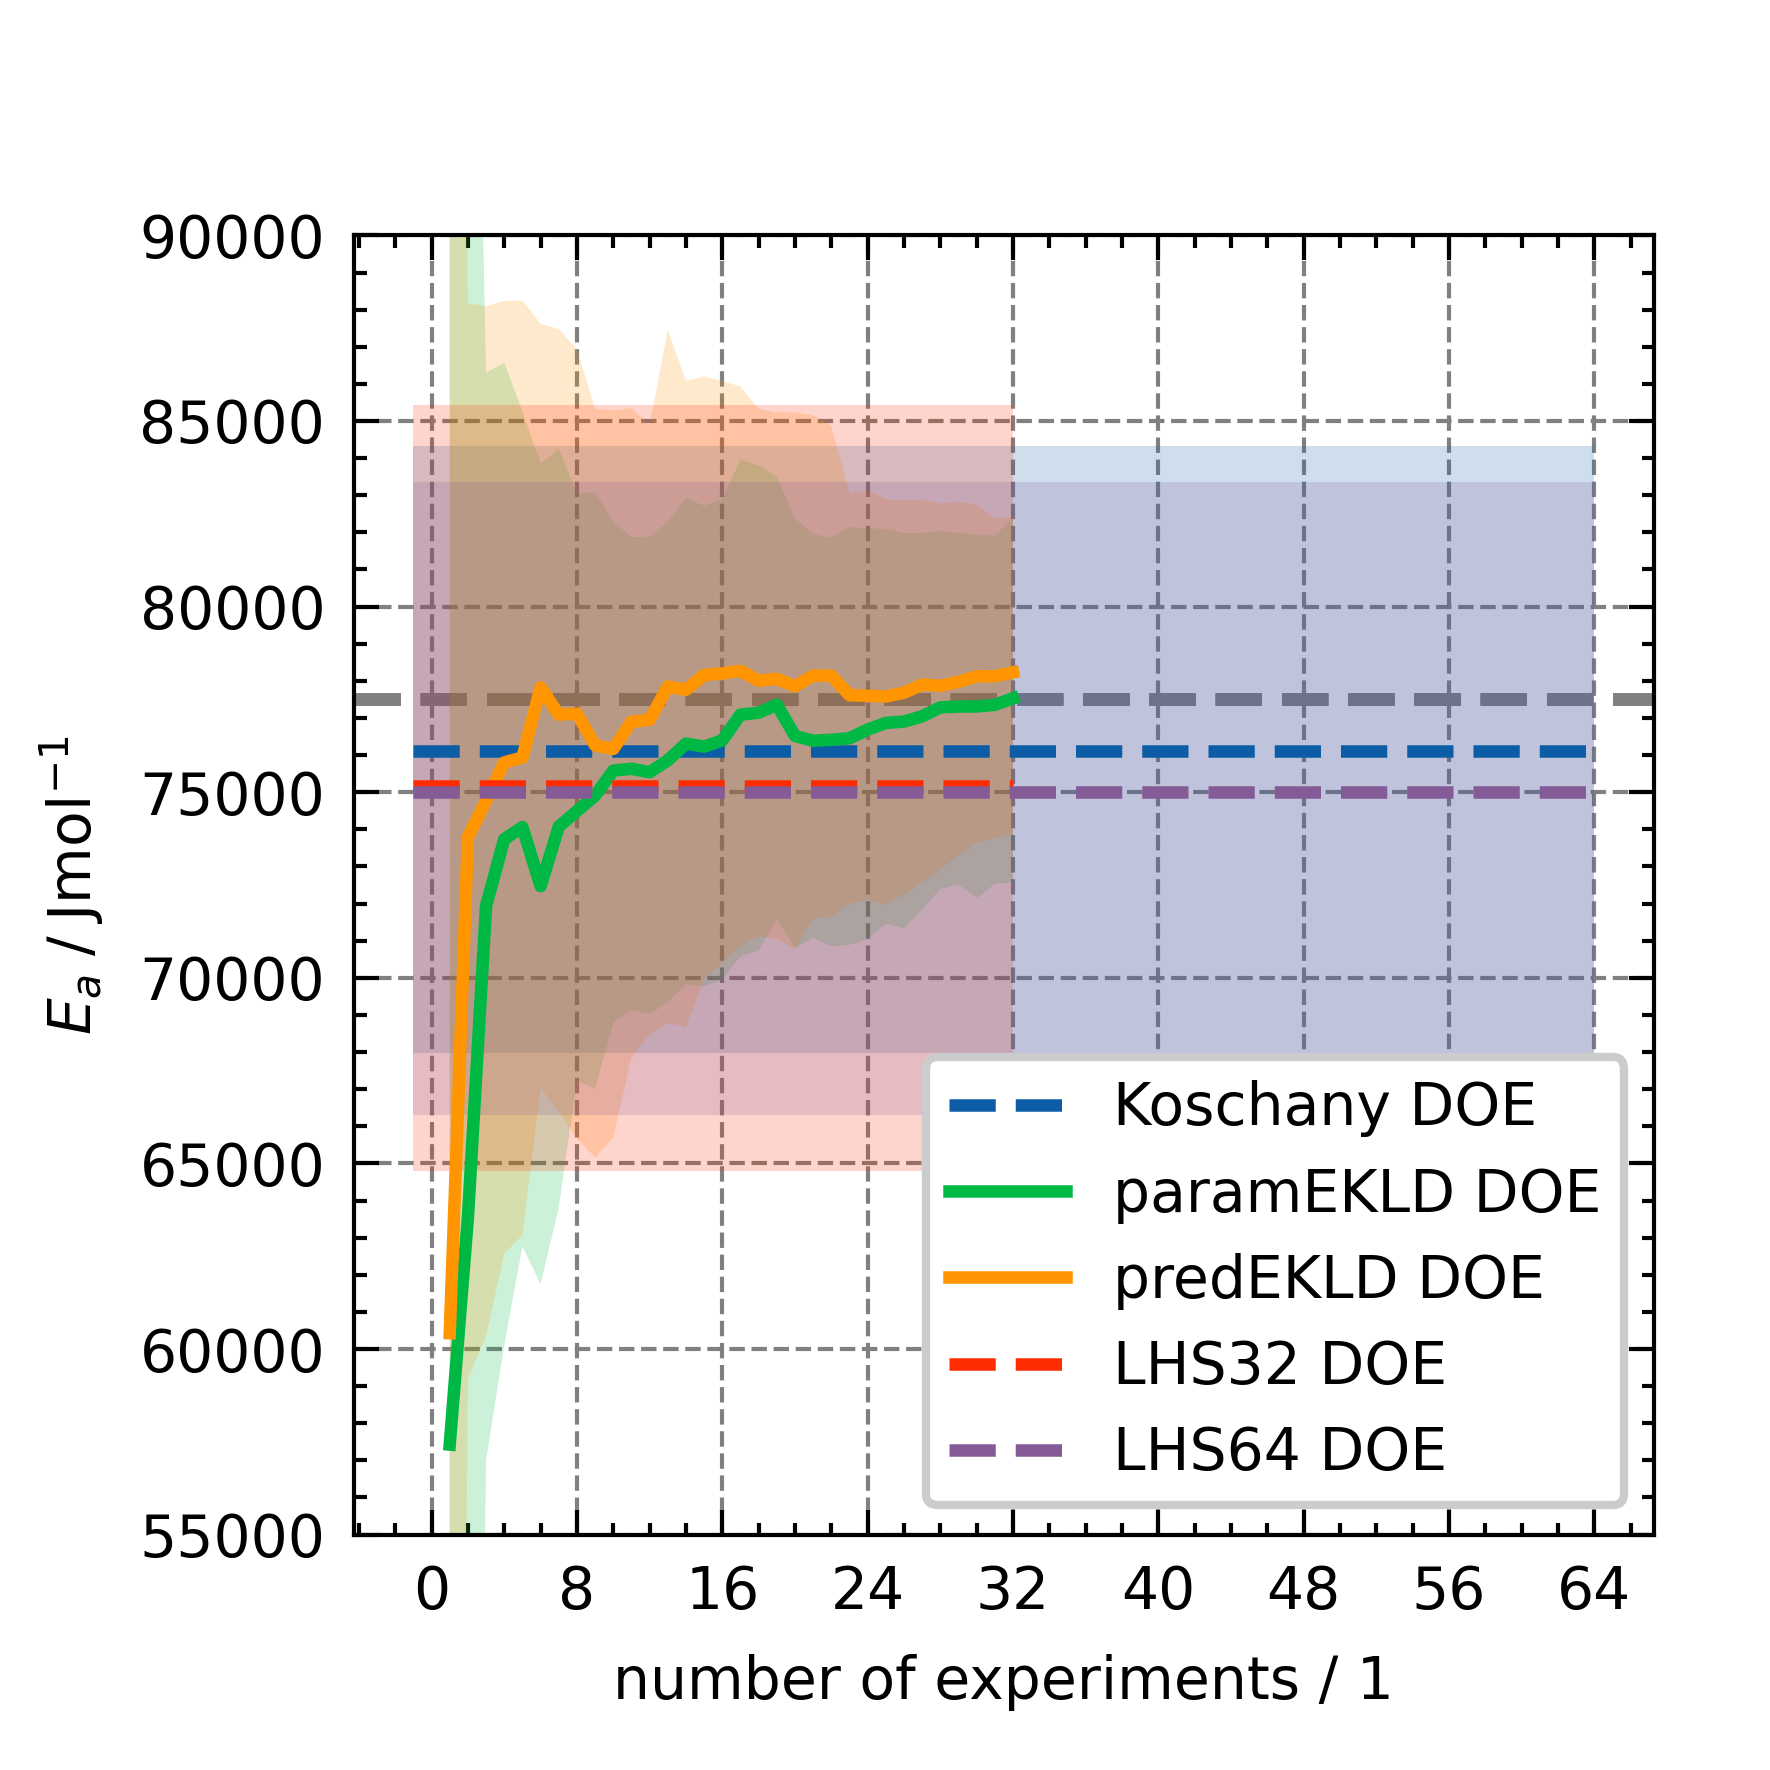

In [ ]:
plot_parameter_evolution("Ea_k")
ax = plt.gca()
ax.set_yscale("linear")
ax.set_ylabel(r"$E_a\;/\; \mathrm{J} \mathrm{mol}^{-1}$")
ax.set_ylim(55000, 90000)
plt.savefig("figures/K/KinFit_Ea_evolution.png")
plt.savefig("figures/K/KinFit_Ea_evolution.pdf")
plt.savefig("figures/K/KinFit_Ea_evolution.svg")

# Do the different seeds agree on the DOE?

In [ ]:
print(ov[1]["DOE"])
print(ov[1]["proposals"].keys())
proposals = list(ov[1]["proposals"].values())
design_order = ("T", "p", "c2h", "c2m", "c2w", "c2i")

paramEKLD DOE
dict_keys([42, 43, 44, 45, 46])


/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")


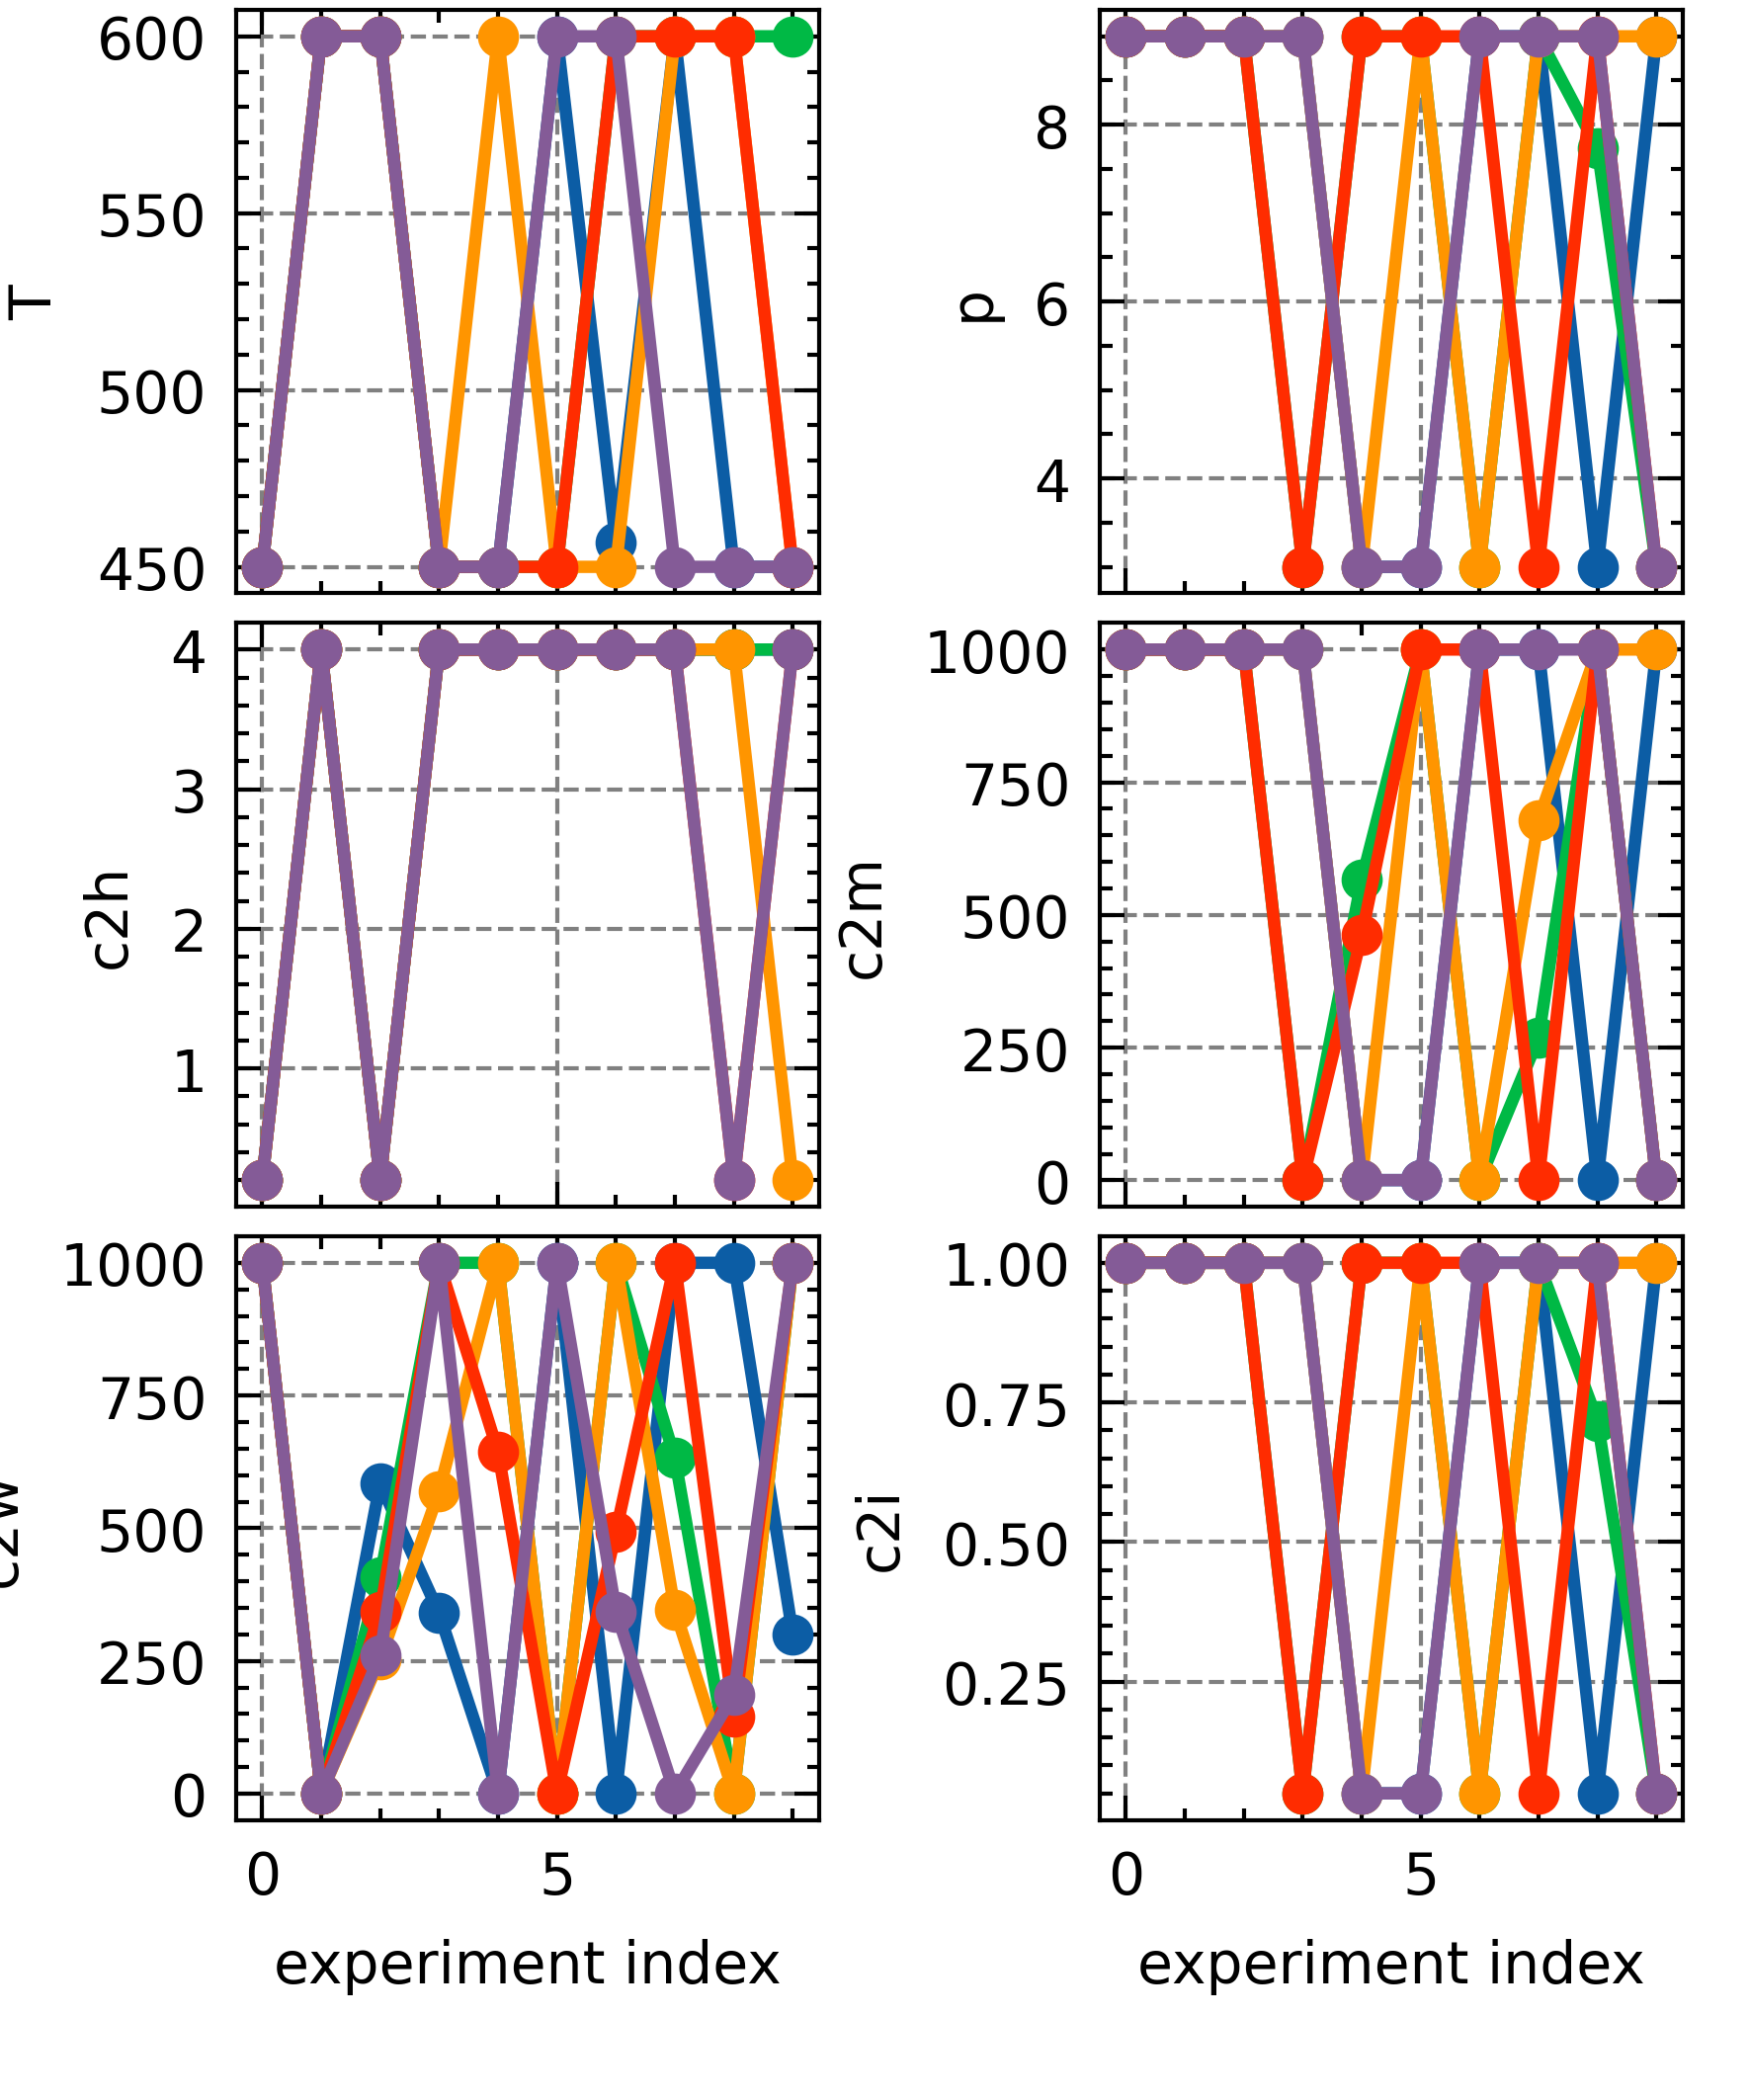

In [ ]:
fig = ICIW_Plots.figure(layout="single_column", height=9 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.5 * ICIW_Plots.cm2inch,
    ax_layout=(3, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.2 * ICIW_Plots.cm2inch,
    left_h=1.01 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

for proposal in proposals:
    for i, design in enumerate(design_order):
        ax = axes[i]
        ax.plot(
            proposal[:10, i],
            label=ov[1]["DOE"],
            # color=colors[1],
            marker="o",
        )
        ax.set_ylabel(f"{design}")
        ax.set_xlabel("experiment index")

No they dont.

# The numbers for the paper:
RMSEs after all experiments

In [ ]:
np.printoptions(precision=3, suppress=True)
# Koschany RMSE
RMSEs = np.concatenate([ov[0]["RMSEs"][seed] for seed in ov[0]["seeds"]], axis=-1)
print(
    f"Koschany DOE after 64 experiments:\n \t mean = {RMSEs[-1,:].mean()} \n\t 95% HDI = {az.hdi(RMSEs[-1,:], prob=0.95)}"
)
print("==================================")

# paramEKLD DOE
RMSEs = np.concatenate([ov[1]["RMSEs"][seed] for seed in ov[1]["seeds"]], axis=-1)
i = 29
print(
    f"paramEKLD DOE after {i:2d} experiments:\n \t mean = {RMSEs[i,:].mean()} \n\t 95% HDI = {az.hdi(RMSEs[i,:], prob=0.95)}"
)
print(
    f"paramEKLD DOE after {10:2d} experiments:\n \t mean = {RMSEs[10,:].mean()} \n\t 95% HDI = {az.hdi(RMSEs[10,:], prob=0.95)}"
)
print("==================================")

# predEKLD DOE
RMSEs = np.concatenate([ov[2]["RMSEs"][seed] for seed in ov[2]["seeds"]], axis=-1)
i = 26
print(
    f"predEKLD DOE after {i:2d} experiments:\n \t mean = {RMSEs[i,:].mean()} \n\t 95% HDI = {az.hdi(RMSEs[i,:], prob=0.95)}"
)
print(
    f"predEKLD DOE after {10:2d} experiments:\n \t mean = {RMSEs[10,:].mean()} \n\t 95% HDI = {az.hdi(RMSEs[10,:], prob=0.95)}"
)
print("==================================")
# LHS64 DOE
RMSEs = np.concatenate([ov[4]["RMSEs"][seed] for seed in ov[4]["seeds"]], axis=-1)
i = 63
print(
    f"LHS64 DOE after {64:2d} experiments:\n \t mean = {RMSEs[i,:].mean()} \n\t 95% HDI = {az.hdi(RMSEs[i,:], prob=0.95)}"
)
print(
    f"LHS64 DOE after {10:2d} experiments:\n \t mean = {RMSEs[10,:].mean()} \n\t 95% HDI = {az.hdi(RMSEs[10,:], prob=0.95)}"
)
print("==================================")

RMSEs after 10 experiments:

In [ ]:
# R-hat per trace (8 chains of one MCMC run), then summarised over the seeds.
# Traces do not store R-hat, so it is computed from the chain structure here.
# Never pool seeds/steps before this: they are different posteriors.
print("groups in a trace:", list(ov[0]["idatas"][ov[0]["seeds"][0]][0].groups()))


def rhat_per_param(idata, group="posterior"):
    """R-hat for every parameter of one trace, as a (n_params,) array."""
    rh = az.rhat(idata[group], var_names=list(PARAM_ORDER))
    return np.array([float(rh[p]) for p in PARAM_ORDER])


for ov_dict in ov:
    # rhat[seed]: (n_steps, n_params)
    ov_dict["rhat"] = {
        seed: np.array([rhat_per_param(idata) for idata in ov_dict["idatas"][seed]])
        for seed in ov_dict["seeds"]
    }

THRESH = 1.01
for ov_dict in ov:
    print(f"\n{ov_dict['ID']} {ov_dict['DOE']}  (R-hat = worst parameter per trace)")
    print(f"  {'seed':>5} {'final step':>11} {'max over steps':>15} {'#steps>' + str(THRESH):>10}")
    worst = {seed: ov_dict["rhat"][seed].max(axis=1) for seed in ov_dict["seeds"]}
    for seed in ov_dict["seeds"]:
        w = worst[seed]
        print(f"  {seed:>5} {w[-1]:>11.4f} {w.max():>15.4f} {(w > THRESH).sum():>10d}")
    finals = np.array([worst[s][-1] for s in ov_dict["seeds"]])
    overall = np.array([worst[s].max() for s in ov_dict["seeds"]])
    print(f"  final step:     min = {finals.min():.4f}   max = {finals.max():.4f}")
    print(f"  max over steps: min = {overall.min():.4f}   max = {overall.max():.4f}")

# Which parameter is the worst, at the final step, over all campaigns and seeds
print("\nWorst R-hat per parameter at the final step (max over seeds):")
for ov_dict in ov:
    per_param = np.max([ov_dict["rhat"][s][-1] for s in ov_dict["seeds"]], axis=0)
    print(f"  {ov_dict['ID']:>6}  " + "  ".join(f"{p}={v:.3f}" for p, v in zip(PARAM_ORDER, per_param)))
